# **Pós-Graduação em Dára Science and Digital Transformation**

## *Ambientes de Programação para Ciência de Dados*
### Projeto 1
---
Ana Estreia

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## PRIMEIRA PARTE
A primeira parte do trabalho consiste na utilização de Python e suas bibliotecas para explorar e
interpretar a informação que consta nos dois ficheiros.<br>
Realize uma análise inicial aos dados constantes em ambos os ficheiros e interprete o seu conteúdo,
respondendo a questões como:<br>
### incendios_sc.csv
1. Qual é a dimensão do conjunto de dados?


In [ ]:
df_incendios = pd.read_csv('incendios_sv.csv', sep=',')
df_incendios.shape
# resposta: (9468639, 4)

(9468639, 4)

2. Qual o nome das colunas e que tipo de dados que lhe estão associados?

In [ ]:
df_incendios.info()
# resposta:
# coluna    tipo
# DataHora  object
# Satelite  object
# Municipi  object
# RiscoFog  float64

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9468639 entries, 0 to 9468638
Data columns (total 4 columns):
 #   Column    Dtype  
---  ------    -----  
 0   DataHora  object 
 1   Satelite  object 
 2   Municipi  object 
 3   RiscoFog  float64
dtypes: float64(1), object(3)
memory usage: 289.0+ MB


3. Existem valores NaN? Se sim, em quantidade significativa? Em que colunas?

In [ ]:
df_incendios.isna().sum()
df_incendios['RiscoFog'].isna().sum()
# resposta: sim, na coluna RiscoFog em cerca de 1.7% dos registos (159123)

,0
DataHora,0
Satelite,0
Municipi,0
RiscoFog,159123


4. Qual é o intervalo temporal a que o conjunto de dados se reporta?

In [ ]:
print(df_incendios.DataHora.min())
print(df_incendios.DataHora.max())
# resposta: de 01/01/2018 a 31/12/2022

2018/01/01 00:04:15
2022/12/31 18:10:00


5. Analise os dados da coluna “Satelite” para dar resposta às questões:<br>
a. Quais são os satélites dominantes no dataset?

In [ ]:
df_incendios.Satelite.value_counts().sort_values(ascending=False).head()
# resposta: GOES-16, NOAA-20, NPP-375, NPP-375D, AQUA_M-T

,count
Satelite,
GOES-16,2853133
NOAA-20,2376293
NPP-375,2049621
NPP-375D,852261
AQUA_M-T,450805


b. Os satélites disponíveis foram sempre os mesmos ao longo dos anos, ou houve
alterações? Se sim, quais

In [ ]:
df_incendios['Ano'] = pd.to_datetime(df_incendios['DataHora'], format='%Y/%m/%d %H:%M:%S').dt.year
df_incendios.head()

,DataHora,Satelite,Municipi,RiscoFog,Ano
0,2018/01/01 00:04:15,GOES-16,MARCELANDIA,0.00,2018
1,2018/01/01 00:29:09,GOES-13,MAUES,NaN,2018
2,2018/01/01 00:29:09,GOES-13,MAUES,0.03,2018
3,2018/01/01 00:54:55,METOP-B,TAILANDIA,0.00,2018
4,2018/01/01 01:31:29,GOES-13,PARECIS,0.25,2018


In [ ]:

satelites_ano = df_incendios.groupby('Ano')['Satelite'].unique()



In [ ]:
for i in range(len(satelites_ano)-1 ):
  ano = satelites_ano.index[i]
  ano_proximo = satelites_ano.index[i+1]

  satelites = satelites_ano.iloc[i]
  satelites_proximo = satelites_ano.iloc[i+1]

  diff_add = set(satelites_proximo) - set(satelites)
  diff_remove = set(satelites) - set(satelites_proximo)
  if diff_add or diff_remove:
    print(f"Alterações de {ano} para {ano_proximo}:")
    if diff_add:
      print(f"  Novos satélites: {diff_add}")
    if diff_remove:
      print(f"  Satélites indisponíveis: {diff_remove}")
  else:
    print(f"Sem alterações de {ano} para {ano_proximo}.")

Alterações de 2018 para 2019:
  Novos satélites: {'NPP-375D', 'METOP-C', 'NOAA-20'}
  Satélites indisponíveis: {'GOES-13'}
Alterações de 2019 para 2020:
  Satélites indisponíveis: {'NOAA-15', 'NOAA-15D'}
Sem alterações de 2020 para 2021.
Sem alterações de 2021 para 2022.


c. Qual é o satélite mais antigo registado no dataset? Encontra-se ainda em operação?

In [ ]:
df_incendios.groupby('Satelite')['DataHora'].min().sort_values().head()
# resposta: GOES-16

,DataHora
Satelite,
GOES-16,2018/01/01 00:04:15
GOES-13,2018/01/01 00:29:09
METOP-B,2018/01/01 00:54:55
TERRA_M-M,2018/01/01 02:35:00
NPP-375,2018/01/01 04:06:00


In [ ]:
ultimo_ano = df_incendios['Ano'].max()
setelites_ultimo_ano = satelites_ano.loc[ultimo_ano]

goes16_active = 'GOES-16' in setelites_ultimo_ano
goes16_active
# resposta: ainda se encontra em operação no último ano

True

d. Existem satélites que deixaram de operar? Quais

In [ ]:
#resposta: a partir da alínea b. sabemos que os satélites GOES-13, NOAA-15D e NOAA-15 deixaram de operar

### estados.csv
1. Qual é o tamanho total do dataset (número de linhas e colunas)?

In [ ]:
df_estados = pd.read_csv('estados.csv', sep=',')
df_estados.shape
# resposta: 550 linhas e 2 colunas

(550, 2)

2. Quantos municípios e quantos estados estão representados no dataset?

In [ ]:
n_estados = len(df_estados.Estado.unique())
n_municipios = len(df_estados.Municipio.unique())
print(f'Estados: {n_estados}')
print(f'Municipios: {n_municipios}')

Estados: 9
Municipios: 546


3. Existem nomes de municípios ou estados repetidos? Identifique-os.

In [ ]:
df_estados.Municipio.value_counts().sort_values(ascending=False).head()

,count
Municipio,
ARAGUANA,2
PAU D'ARCO,2
PRESIDENTE MEDICI,2
RIO BRANCO,2
SANTA ROSA DO PURUS,1


4. O dataset contém valores NaN?


In [ ]:
df_estados.isna().sum()
# resposta: não

,0
Estado,0
Municipio,0


## SEGUNDA PARTE
A segunda parte do trabalho consiste em analisar os focos de incêndio temporal e espacialmente.<br>
1. Comece por criar um conjunto de dados (a gravação para ficheiro .csv é opcional) com as
seguintes colunas: Ano, Mês, Estado, Nº de ocorrências.<br>
A partir deste novo conjunto de dados, analise os seguintes aspetos, apresentando evidências que
sustentem as conclusões:


In [ ]:
df_incendios['Mês'] = pd.to_datetime(df_incendios['DataHora'], format='%Y/%m/%d %H:%M:%S').dt.month
df_merged = pd.merge(df_incendios, df_estados, left_on='Municipi', right_on='Municipio')
#df_merged.head()



In [ ]:
df_ocorrencias = df_merged.groupby(['Ano', 'Mês', 'Estado']).count()
df_ocorrencias.drop(['Satelite', 'Municipi','RiscoFog','Municipio'], axis=1, inplace=True)
df_ocorrencias.rename(columns={'DataHora': 'Nº de ocorrências'}, inplace=True)
df_ocorrencias.reset_index(inplace=True)
df_ocorrencias.head()

,Ano,Mês,Estado,Nº de ocorrências
0,2018,1,ACRE,31
1,2018,1,AMAPA,90
2,2018,1,AMAZONAS,324
3,2018,1,MARANHAO,1448
4,2018,1,MATO GROSSO,2187



2. Evolução anual dos incêndios<br>
a. Como evoluiu o número total de incêndios ao longo dos anos?

In [ ]:
ocorrencias_totais = df_ocorrencias.groupby('Ano')['Nº de ocorrências'].sum()
#ocorrencias_totais

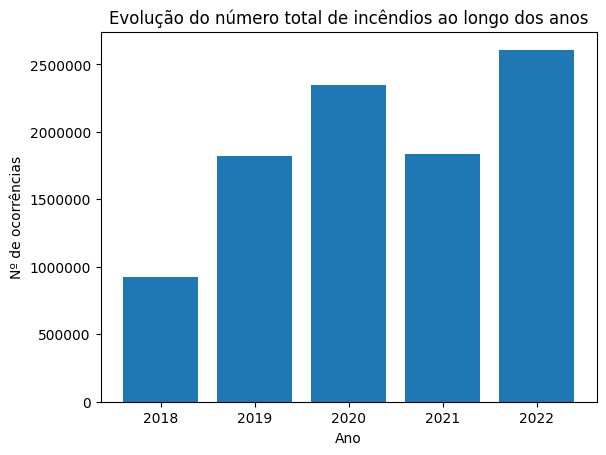

In [ ]:

fig, ax = plt.subplots()

ax.bar(ocorrencias_totais.index, ocorrencias_totais.values)
ax.set_ylabel('Nº de ocorrências')
ax.set_xlabel('Ano')
ax.set_title('Evolução do número total de incêndios ao longo dos anos')
ax.ticklabel_format(style='plain')

plt.show()
# resposta: tem vindo a aumentar, com um pequeno declíneo em 2021

b. Observa-se alguma tendência significativa?

In [ ]:
# Resposta: Sim, observa-se uma tendência geral de aumento no número de ocorrências, com o maior valor em 2022.

c. Em que anos se registaram o menor e o maior número de ocorrências?


In [ ]:
max = ocorrencias_totais.max()
min = ocorrencias_totais.min()


year_max =ocorrencias_totais[ocorrencias_totais == max].index[0]
year_min = ocorrencias_totais[ocorrencias_totais == min].index[0]

print(f"Ano com maior número de ocorrências: {year_max}")
print(f"Ano com menor número de ocorrências: {year_min}")

Ano com maior número de ocorrências: 2022
Ano com menor número de ocorrências: 2018


3. Distribuição mensal e análise por estado<br>
a. Como se distribui o número de incêndios ao longo dos meses do ano (usar os valores
médios no período representado)?

In [ ]:
ocorrencias_mensais_medias = df_ocorrencias.groupby('Mês')['Nº de ocorrências'].mean()
#ocorrencias_mensais_medias


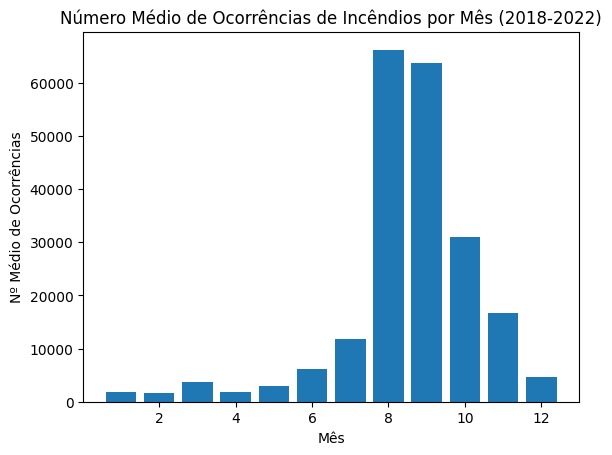

In [ ]:
fig, ax = plt.subplots()

ax.bar(ocorrencias_mensais_medias.index, ocorrencias_mensais_medias.values)
ax.set_ylabel('Nº Médio de Ocorrências')
ax.set_xlabel('Mês')
ax.set_title('Número Médio de Ocorrências de Incêndios por Mês (2018-2022)')

plt.show()
# resposta: existe uma subida significativa nos meses de verão, especialmente em agosto e setembro

b. Para cada estado, determine: o número total de incêndios, o valor médio e o desviopadrão das ocorrências.

In [ ]:
analise_estados = df_ocorrencias.groupby('Estado')['Nº de ocorrências'].agg(['sum', 'mean', 'std'])
analise_estados


,sum,mean,std
Estado,,,
ACRE,451957,7532.616667,15788.508139
AMAPA,61173,1019.550000,2059.928240
AMAZONAS,1407061,23451.016667,50292.458544
MARANHAO,386239,6437.316667,9365.455471
MATO GROSSO,2266448,37774.133333,56831.060544
PARA,3354253,55904.216667,86873.190791
RONDONIA,1235311,20588.516667,36471.990974
RORAIMA,316812,5280.200000,13925.525682
TOCANTINS,55626,927.100000,1642.898490


c. Que estados apresentam o maior e o menor número de incêndios?

In [ ]:
max = analise_estados['sum'].max()
min = analise_estados['sum'].min()

estado_max = analise_estados[analise_estados['sum'] == max].index[0]
estado_min = analise_estados[analise_estados['sum'] == min].index[0]

print(f'Estado com maior número de ocorrências: {estado_max}')
print(f'Estado com menor número de ocorrências: {estado_min}')

Estado com maior número de ocorrências: PARA
Estado com menor número de ocorrências: TOCANTINS


4. Análise temporal dos estados extremos: considerando os estados identificados na questão
anterior, analise a evolução anual do número de incêndios em cada um deles.

In [ ]:
ocorrencias_max=df_ocorrencias[df_ocorrencias.Estado == estado_max]
max_data =ocorrencias_max.groupby('Ano')['Nº de ocorrências'].sum()


In [ ]:
ocorrencias_min=df_ocorrencias[df_ocorrencias.Estado == estado_min]
min_data =ocorrencias_min.groupby('Ano')['Nº de ocorrências'].sum()


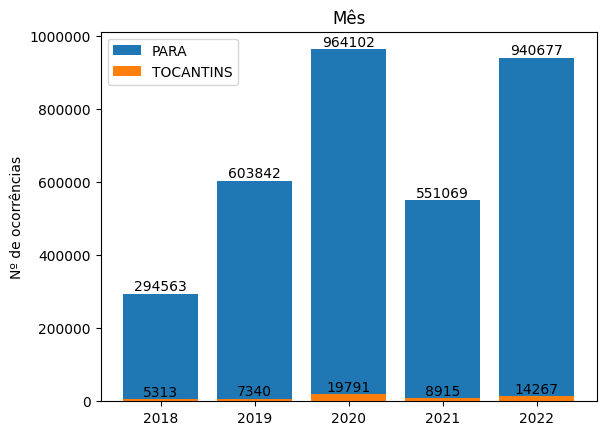

In [ ]:
fig, ax = plt.subplots()


ax.ticklabel_format(style='plain')
rects1 = ax.bar(max_data.index, max_data.values, label=estado_max)
rects2 = ax.bar(min_data.index, min_data.values,label=estado_min)


ax.set_ylabel('Nº de ocorrências')
ax.set_title('Mês')


ax.legend()
ax.bar_label(rects1)
ax.bar_label(rects2)
plt.show()

